# Trabajo Practico 4 - Aprendizaje No Supervisado

**Alumno:** Tomas Gonzalez  
**Materia:** I302 - Machine Learning y Deep Learning

En este notebook resuelvo la parte computacional del TP4. La idea es ir construyendo el analisis desde la inspeccion inicial de Fashion-MNIST hasta reduccion de dimensionalidad y clustering. Las implementaciones pedidas desde cero quedan en `numpy`; PyTorch aparece solamente en los autoencoders, que es donde la consigna lo permite.

Para que el notebook no sea un bloque enorme de codigo, separe funciones en:

- `src/tp4_data.py`: lectura del dataset, nombres de clases y splits estratificados.
- `src/tp4_linear.py`: estandarizacion, PCA, reconstruccion y distancias.
- `src/tp4_clustering.py`: k-Means, GMM diagonal, Silhouette y resumen de clusters.
- `src/tp4_tsne.py`: implementacion propia de t-SNE.
- `src/tp4_torch_models.py` y `src/tp4_torch_train.py`: modelos, entrenamiento y uso de AE/beta-VAE.
- `src/tp4_plots.py`: funciones de graficos y guardado de figuras.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("src")

from tp4_data import (
    LABEL_NAMES,
    as_images,
    load_fashion_mnist_subset,
    stratified_sample_indices,
    stratified_train_eval_split,
)
from tp4_linear import (
    fit_pca,
    fit_standardizer,
    inverse_standardizer,
    n_components_for_variance,
    pairwise_distances,
    pca_inverse_transform,
    pca_transform,
    reconstruction_mse,
    transform_standardizer,
)
from tp4_clustering import (
    cluster_class_table,
    cluster_summary,
    gmm_diag,
    kmeans,
    silhouette_score_from_distances,
    total_purity,
)
from tp4_tsne import (
    tsne_embedding,
)
from tp4_plots import (
    plot_ae_history,
    plot_average_images_by_class,
    plot_class_distribution,
    plot_cluster_heatmap,
    plot_cluster_metrics,
    plot_cluster_sizes,
    plot_images,
    plot_intensity_by_class,
    plot_pca_variance,
    plot_reconstruction_rows,
    plot_samples_by_class,
    plot_tsne,
    plot_vae_history,
    save_figure,
    set_plot_style,
)
from tp4_torch_models import (
    AutoEncoder,
    BetaVAE,
    get_device,
    set_seed,
)
from tp4_torch_train import (
    decode_autoencoder,
    decode_vae,
    encode_autoencoder,
    encode_vae,
    reconstruct_autoencoder,
    reconstruct_vae,
    train_autoencoder,
    train_vae,
)

SEED = 42
np.random.seed(SEED)
set_seed(SEED)
set_plot_style()

DATA_PATH = "data/fashion_mnist_subset.csv"
FIGURES_DIR = Path("figures")
CSV_DIR = Path("csvs")
FIGURES_DIR.mkdir(exist_ok=True)
CSV_DIR.mkdir(exist_ok=True)

device = get_device()

## 1. Inspeccion de los datos

El dataset tiene imagenes de `28 x 28` pixeles en escala de grises. Cada fila contiene 784 intensidades y una etiqueta de clase. Aunque las etiquetas no se usan para entrenar los metodos no supervisados, si sirven para inspeccionar el dataset y para evaluar despues si los clusters tienen una interpretacion razonable.

In [2]:
X, y, df = load_fashion_mnist_subset(DATA_PATH)

resumen = pd.DataFrame(
    {
        "valor": [
            X.shape[0],
            X.shape[1],
            float(X.min()),
            float(X.max()),
            float(X.mean()),
            float(X.std()),
            int(np.isnan(X).sum()),
        ]
    },
    index=[
        "imagenes",
        "pixeles_por_imagen",
        "min_pixel",
        "max_pixel",
        "media_global",
        "std_global",
        "valores_nan",
    ],
)
resumen

,valor
imagenes,25000.000000
pixeles_por_imagen,784.000000
min_pixel,0.000000
max_pixel,1.000000
media_global,0.286593
std_global,0.353334
valores_nan,0.000000


Los pixeles ya vienen normalizados entre 0 y 1. Eso simplifica el entrenamiento de los autoencoders porque la salida puede modelarse con una `Sigmoid`, quedando en el mismo rango que la entrada. Primero miro imagenes sueltas para verificar que la conversion desde filas del CSV a matrices de `28 x 28` sea correcta.

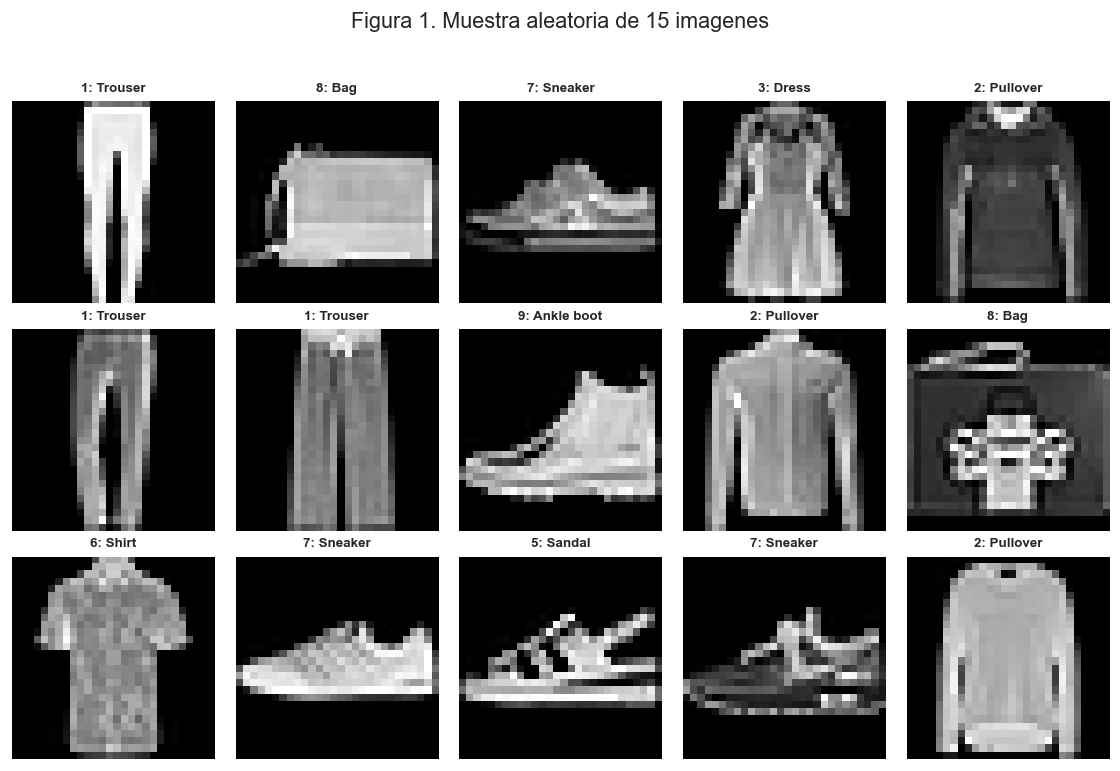

In [3]:
rng = np.random.default_rng(SEED)
idx_fig1 = rng.choice(len(X), size=15, replace=False)
fig = plot_images(
    X[idx_fig1],
    labels=y[idx_fig1],
    n_cols=5,
    title="Figura 1. Muestra aleatoria de 15 imagenes",
)
save_figure(fig, "figura_01_muestra_aleatoria.png", FIGURES_DIR)
plt.show()

**Figura 1. Muestra aleatoria de 15 imagenes.**

Las prendas aparecen centradas y con fondo negro, asi que la lectura del CSV a imagen de `28 x 28` parece estar bien. Lo primero que me llamo la atencion es que varias clases de ropa superior se parecen bastante: `Shirt`, `T-shirt/top`, `Pullover` y `Coat` comparten mucha forma. Por eso ya esperaba que el clustering no separara todo perfecto.

Ahora reviso si el dataset esta balanceado por clase. En un problema no supervisado esto no se usa para ajustar los modelos, pero si cambia como se interpretan los clusters: si una clase estuviera sobrerrepresentada, podria dominar particiones grandes.

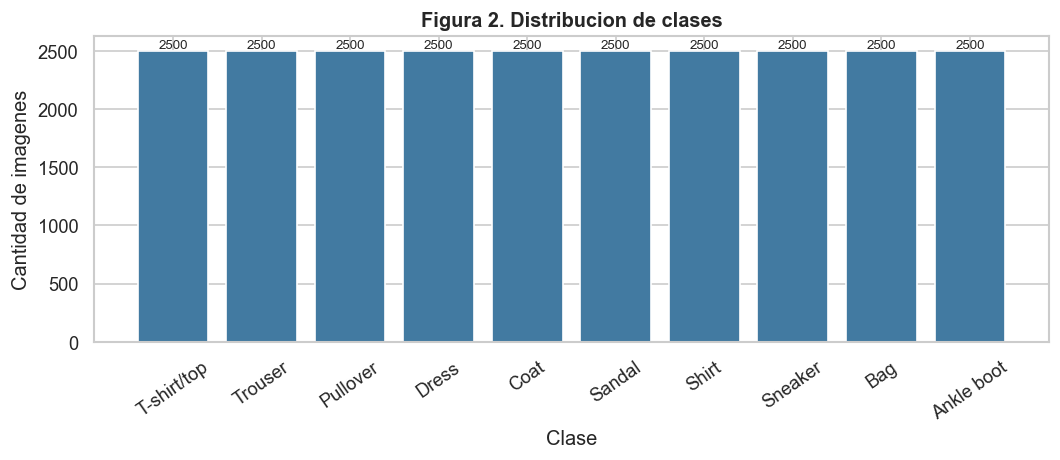

In [4]:
fig = plot_class_distribution(y, title="Figura 2. Distribucion de clases")
save_figure(fig, "figura_02_distribucion_clases.png", FIGURES_DIR)
plt.show()

**Figura 2. Distribucion de clases.**

El dataset esta completamente balanceado: todas las clases tienen la misma cantidad de imagenes. Esto me deja mas tranquilo para la parte de clustering, porque si aparece un cluster grande no va a ser simplemente porque una clase venia con muchos mas datos desde el inicio.

In [5]:
pd.Series(y).value_counts().sort_index().rename(index=LABEL_NAMES).to_frame("cantidad")

,cantidad
T-shirt/top,2500
Trouser,2500
Pullover,2500
Dress,2500
Coat,2500
Sandal,2500
Shirt,2500
Sneaker,2500
Bag,2500
Ankle boot,2500


Para ver variabilidad dentro de cada etiqueta, grafico muestras agrupadas por clase. Elegi clases de ropa superior y una de calzado porque ahi se ve bien el contraste entre clases parecidas y clases mas separables.

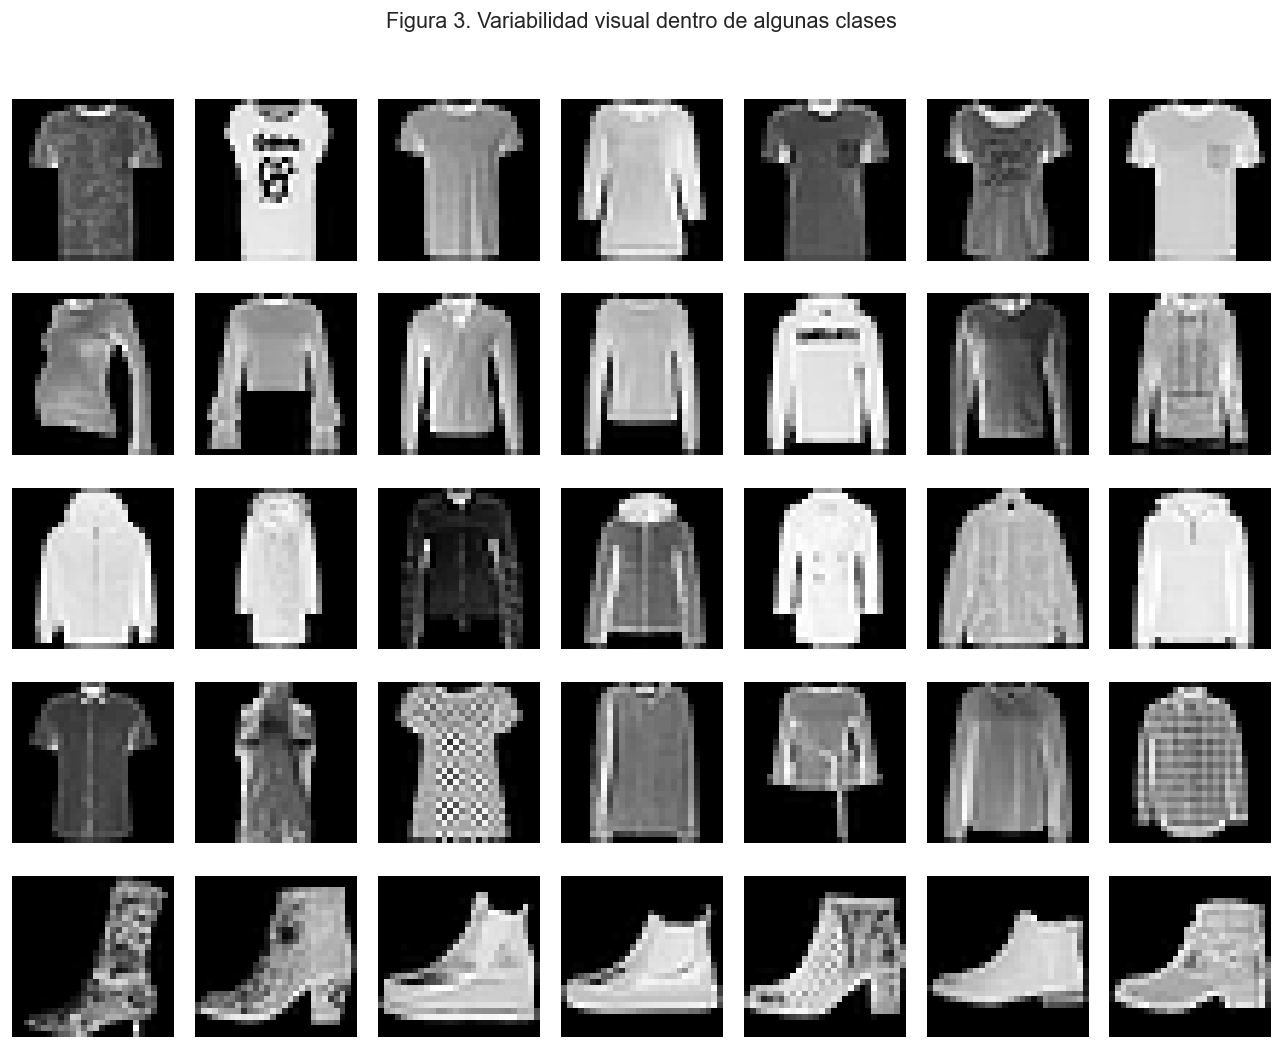

In [6]:
classes_fig3 = [0, 2, 4, 6, 9]
fig = plot_samples_by_class(
    X,
    y,
    classes=classes_fig3,
    n_per_class=7,
    seed=SEED,
    title="Figura 3. Variabilidad visual dentro de algunas clases",
)
save_figure(fig, "figura_03_muestras_por_clase.png", FIGURES_DIR)
plt.show()

**Figura 3. Variabilidad visual dentro de algunas clases.**

Aca se ve que no todas las imagenes de una misma clase son iguales. En ropa superior cambian mangas, ancho y forma del cuello. `Ankle boot`, en cambio, parece bastante mas consistente. Me parecio importante mirarlo porque una clase real puede terminar partida en varios grupos, y tambien varias clases parecidas pueden caer juntas.

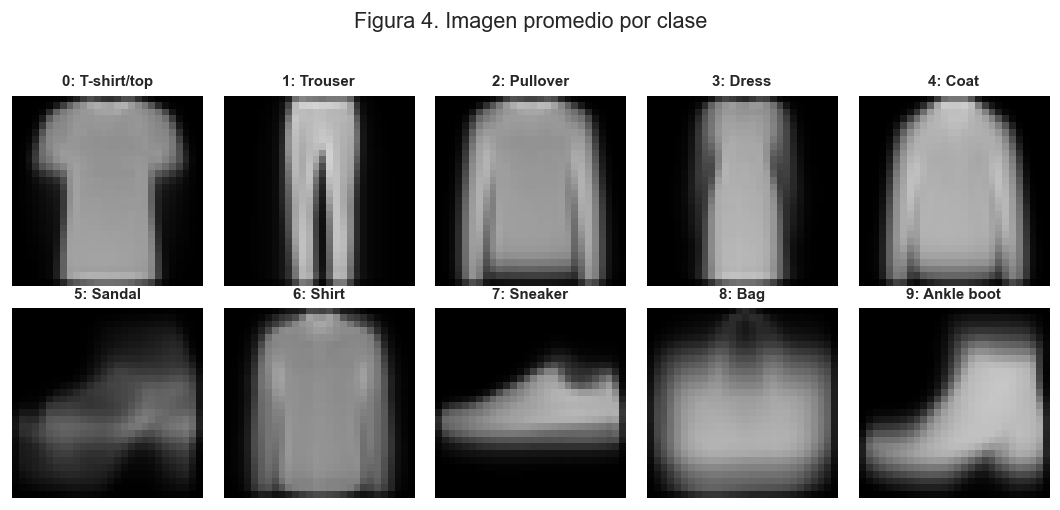

In [7]:
fig = plot_average_images_by_class(
    X,
    y,
    title="Figura 4. Imagen promedio por clase",
)
save_figure(fig, "figura_04_promedios_por_clase.png", FIGURES_DIR)
plt.show()

**Figura 4. Imagen promedio por clase.**

Los promedios sirven como un prototipo rapido de cada clase. Calzado y bolsos quedan bastante claros, pero las prendas superiores se parecen mas entre si. Esto despues ayuda a interpretar por que algunos clusters son mas homogeneos que otros.

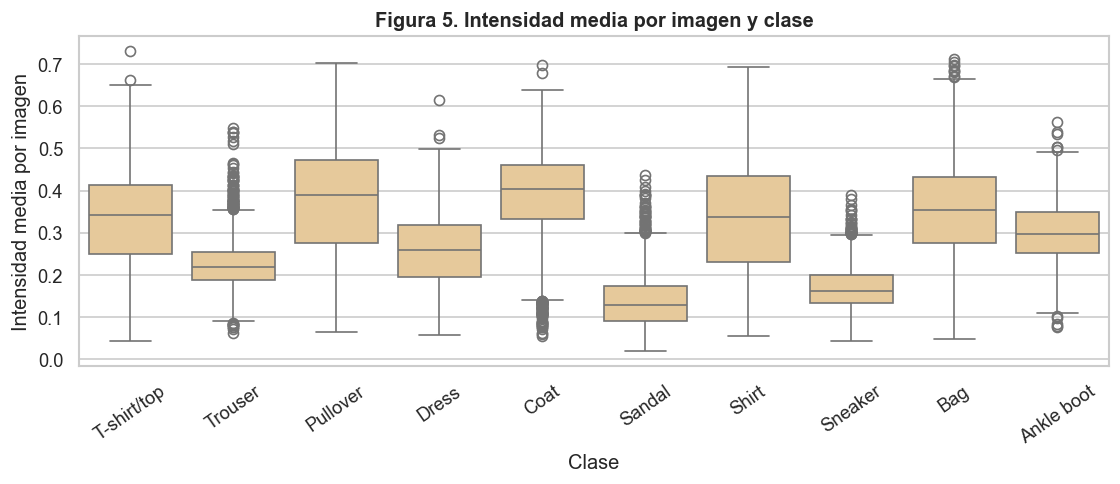

In [8]:
fig = plot_intensity_by_class(
    X,
    y,
    title="Figura 5. Intensidad media por imagen y clase",
)
save_figure(fig, "figura_05_intensidad_por_clase.png", FIGURES_DIR)
plt.show()

**Figura 5. Intensidad media por imagen y clase.**

La intensidad media sola no clasifica nada, pero muestra que algunas clases ocupan mas pixeles claros que otras. Lo use mas como chequeo exploratorio: si despues uso distancias, escala y contraste pueden influir, asi que tiene sentido estandarizar antes de PCA.

### Split estratificado

La consigna pide separar entrenamiento y evaluacion dejando 20% para evaluacion. Uso un split estratificado para conservar la proporcion de clases:

$$
\frac{N_{c,eval}}{N_c} \approx 0.20
$$

Como el dataset esta balanceado, el split deja la misma cantidad de imagenes de cada clase en ambos conjuntos.

In [9]:
train_idx, eval_idx = stratified_train_eval_split(y, eval_size=0.20, seed=SEED)

X_train, y_train = X[train_idx], y[train_idx]
X_eval, y_eval = X[eval_idx], y[eval_idx]

split_table = pd.DataFrame(
    {
        "train": pd.Series(y_train).value_counts().sort_index(),
        "eval": pd.Series(y_eval).value_counts().sort_index(),
    }
).rename(index=LABEL_NAMES)
split_table.loc["TOTAL"] = split_table.sum(axis=0)
split_table

,train,eval
T-shirt/top,2000,500
Trouser,2000,500
Pullover,2000,500
Dress,2000,500
Coat,2000,500
Sandal,2000,500
Shirt,2000,500
Sneaker,2000,500
Bag,2000,500
Ankle boot,2000,500


## 2. Reduccion de dimensionalidad

### 2.a PCA desde cero

Antes de aplicar PCA estandarizo cada pixel usando solo el conjunto de entrenamiento:

$$
x_{ij}^{std} = \frac{x_{ij} - \mu_j}{\sigma_j}
$$

donde $\mu_j$ y $\sigma_j$ son la media y el desvio del pixel $j$ en entrenamiento. Despues calculo la matriz de covarianza:

$$
S = \frac{1}{N-1}\bar{X}^{T}\bar{X}
$$

La direccion de mayor varianza es el autovector asociado al mayor autovalor:

$$
S v_j = \lambda_j v_j
$$

Si guardo los primeros $M$ autovectores en $U_M = [v_1,\dots,v_M]$, la proyeccion queda:

$$
Z = \bar{X} U_M
$$

y la reconstruccion en el espacio estandarizado queda:

$$
\tilde{X}^{std}= ZU_M^T
$$

In [10]:
standardizer = fit_standardizer(X_train)
X_train_std = transform_standardizer(X_train, standardizer)
X_eval_std = transform_standardizer(X_eval, standardizer)

pca = fit_pca(X_train_std)
K_PCA = n_components_for_variance(pca, target=0.90)

pca_info = pd.DataFrame(
    {
        "componentes": [50, 80, K_PCA, 252],
        "varianza_acumulada": [
            pca["cumulative_ratio"][49],
            pca["cumulative_ratio"][79],
            pca["cumulative_ratio"][K_PCA - 1],
            pca["cumulative_ratio"][251],
        ],
    }
)
pca_info

,componentes,varianza_acumulada
0,50,0.800625
1,80,0.850085
2,135,0.900369
3,252,0.950160


Con el criterio de 90% de varianza explicada acumulada se retienen **K = 135** componentes principales. Me parecio un buen compromiso: baja de 784 a 135 dimensiones, pero todavia conserva gran parte de la informacion.

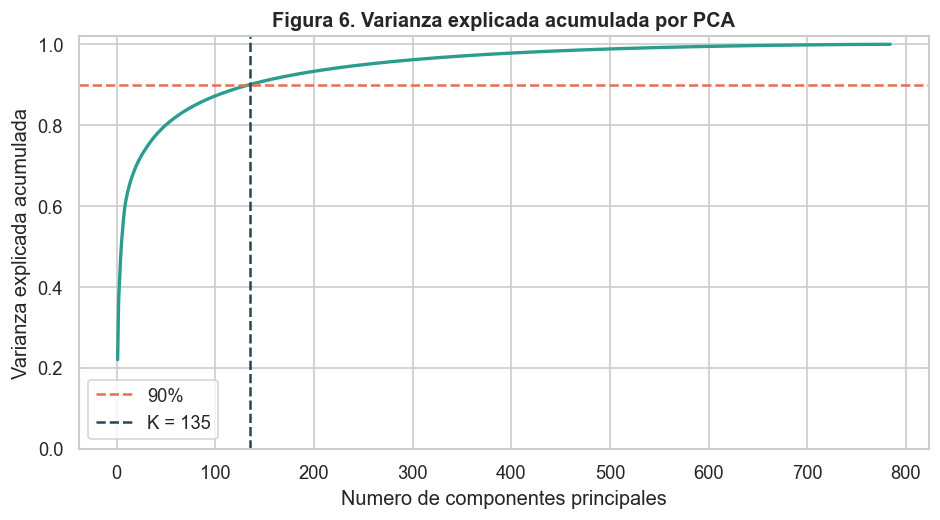

In [11]:
fig = plot_pca_variance(
    pca["cumulative_ratio"],
    K_PCA,
    title="Figura 6. Varianza explicada acumulada por PCA",
)
save_figure(fig, "figura_06_varianza_pca.png", FIGURES_DIR)
plt.show()

**Figura 6. Varianza explicada acumulada por PCA.**

La curva crece rapido al principio y despues se aplana. Interpreto que las primeras componentes capturan la forma grande de las prendas, y las demas agregan detalles cada vez mas chicos. El umbral de 90% queda en $K=135$, que use como dimension latente para comparar PCA, AE y beta-VAE.

### 2.b Reconstruccion con PCA

Para reconstruir desde PCA uso las $K$ componentes anteriores. Primero vuelvo al espacio estandarizado:

$$
\tilde{X}^{std}=ZU_K^T
$$

Despues aplico la inversa de la estandarizacion para regresar al rango de imagen original:

$$
\tilde{X}= \tilde{X}^{std}\sigma + \mu
$$

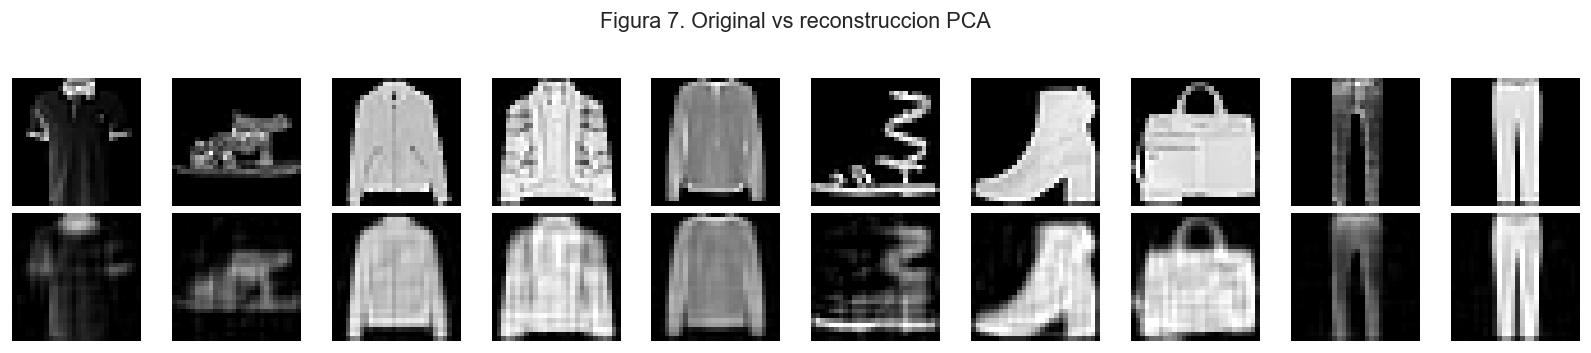

In [12]:
Z_train_pca = pca_transform(X_train_std, pca, K_PCA)
Z_eval_pca = pca_transform(X_eval_std, pca, K_PCA)

X_eval_pca_std_hat = pca_inverse_transform(Z_eval_pca, pca, K_PCA)
X_eval_pca_hat = inverse_standardizer(X_eval_pca_std_hat, standardizer)
X_eval_pca_hat = np.clip(X_eval_pca_hat, 0, 1)

rng = np.random.default_rng(SEED)
idx_recon = rng.choice(len(X_eval), size=10, replace=False)

mse_pca = reconstruction_mse(X_eval[idx_recon], X_eval_pca_hat[idx_recon])

fig = plot_reconstruction_rows(
    X_eval[idx_recon],
    {"PCA": X_eval_pca_hat[idx_recon]},
    ["PCA"],
    title="Figura 7. Original vs reconstruccion PCA",
    n=10,
)
save_figure(fig, "figura_07_reconstruccion_pca.png", FIGURES_DIR)
plt.show()

**Figura 7. Original vs reconstruccion PCA.**

PCA recupera bastante bien la silueta general. Lo que mas se nota es que las imagenes reconstruidas quedan mas suaves, sobre todo en bordes y detalles internos. En estas 10 imagenes el MSE es **0.00944**, que me parecio bajo considerando que pase de 784 a 135 variables.

In [13]:
pd.DataFrame({"MSE_10_imagenes": [mse_pca]}, index=["PCA"])

,MSE_10_imagenes
PCA,0.009442


### 2.c Autoencoder deterministico

El autoencoder deterministico usa dos redes:

$$
z = \phi_e(x; w_e)
$$

$$
\tilde{x} = \phi_d(z; w_d)
$$

La dimension de $z$ se fija igual a la cantidad de componentes retenidas por PCA, es decir $K=135$. Entreno durante 150 epochs minimizando error cuadratico medio:

$$
\mathcal{L}_{AE} = \frac{1}{N}\sum_{i=1}^{N}\lVert x_i - \tilde{x}_i\rVert^2
$$

Uso imagenes normalizadas entre 0 y 1 y una salida `Sigmoid`, asi la reconstruccion queda en el mismo rango. Al aumentar las epochs busco que el AE tenga mas tiempo para ajustar la reconstruccion y que la comparacion contra PCA sea mas razonable.

In [14]:
set_seed(SEED)
ae = AutoEncoder(latent_dim=K_PCA)
ae_history = train_autoencoder(
    ae,
    X_train,
    X_eval,
    epochs=150,
    batch_size=256,
    lr=1e-3,
    device=device,
)

ae_history.to_csv(CSV_DIR / "ae_history.csv", index=False)
ae_history.tail()

,epoch,train_mse,val_mse
145,146,0.006022,0.007765
146,147,0.006018,0.007781
147,148,0.005976,0.007743
148,149,0.006005,0.007717
149,150,0.005928,0.007757


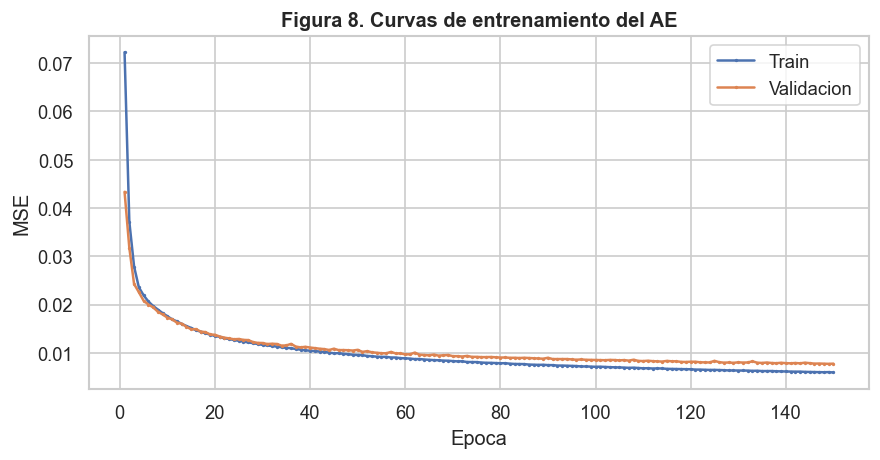

In [15]:
fig = plot_ae_history(ae_history, title="Figura 8. Curvas de entrenamiento del AE")
save_figure(fig, "figura_08_curvas_ae.png", FIGURES_DIR)
plt.show()

**Figura 8. Curvas de entrenamiento del AE.**

Con 150 epochs el AE sigue bajando el error durante buena parte del entrenamiento. La curva de validacion termina en **0.00776** y la de entrenamiento en **0.00593**. Hay una diferencia chica entre train y validacion, esperable al entrenar mas tiempo, pero no veo una subida sostenida de validacion. Achique los puntos del grafico porque con tantas epochs se superponian mucho.

In [16]:
X_eval_ae_hat = reconstruct_autoencoder(ae, X_eval, device=device)
mse_ae = reconstruction_mse(X_eval[idx_recon], X_eval_ae_hat[idx_recon])

pd.DataFrame(
    {"MSE_10_imagenes": [mse_ae]},
    index=["AE"],
)

,MSE_10_imagenes
AE,0.010136


### 2.d Comparacion PCA vs AE

La comparacion es justa porque PCA y AE usan la misma dimension latente. La diferencia principal es que PCA solo puede hacer una proyeccion lineal, mientras que el AE puede aprender una transformacion no lineal.

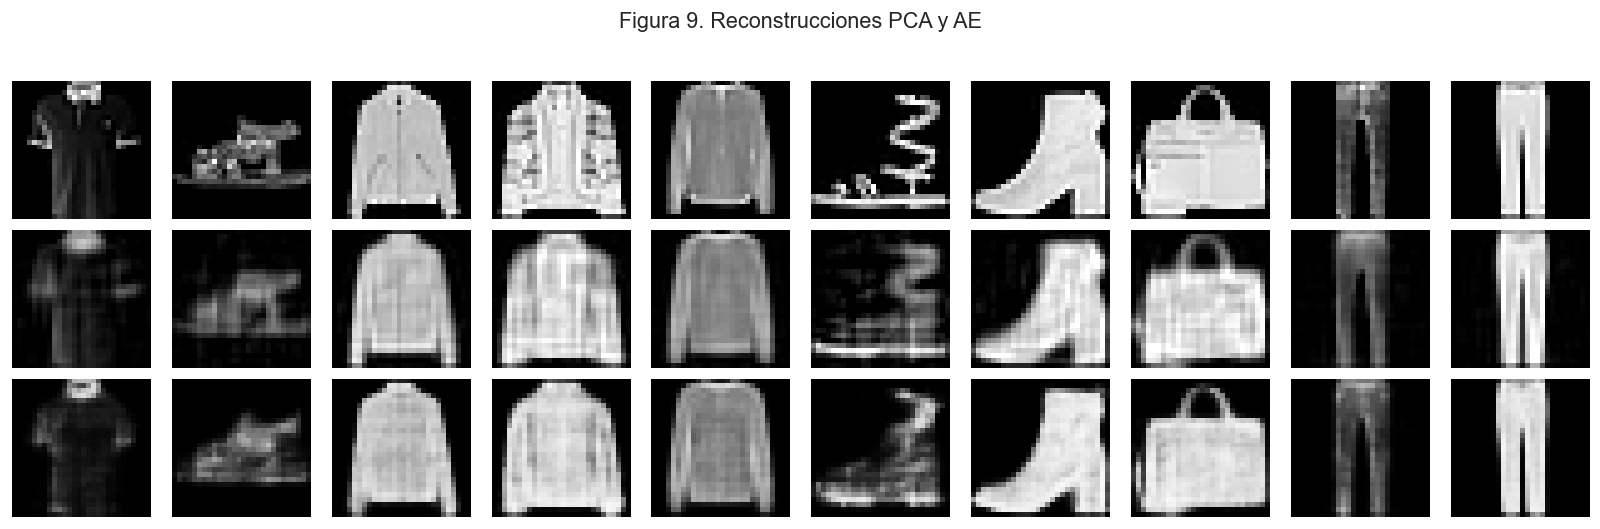

In [17]:
fig = plot_reconstruction_rows(
    X_eval[idx_recon],
    {
        "PCA": X_eval_pca_hat[idx_recon],
        "AE": X_eval_ae_hat[idx_recon],
    },
    ["PCA", "AE"],
    title="Figura 9. Reconstrucciones PCA y AE",
    n=10,
)
save_figure(fig, "figura_09_reconstrucciones_pca_ae.png", FIGURES_DIR)
plt.show()

**Figura 9. Reconstrucciones PCA y AE.**

Despues de entrenar 150 epochs, el AE queda bastante cerca de PCA. En estas 10 imagenes PCA mantiene un MSE apenas menor (**0.00944** contra **0.01014** del AE), pero visualmente la diferencia ya no es grande. Me quedo con que PCA es muy fuerte para reconstruccion lineal global, y que el AE necesita entrenamiento para acercarse.

In [18]:
pd.DataFrame(
    {"MSE_10_imagenes": [mse_pca, mse_ae]},
    index=["PCA", "AE"],
)

,MSE_10_imagenes
PCA,0.009442
AE,0.010136


### 2.e Espacios latentes para los siguientes puntos

Para acelerar el clustering trabajo con representaciones de dimension $K$, no con los 784 pixeles originales:

- `Z_pca`: proyeccion PCA aprendida con entrenamiento.
- `Z_ae`: salida del encoder del AE.

En PCA conservo los scores crudos, porque la escala de cada componente ya representa cuanta varianza explica. Si los estandarizara, una componente de baja varianza pesaria tanto como la primera componente principal. En AE si estandarizo el latente, porque su escala depende de la red y no tiene una interpretacion directa.

In [19]:
X_all_std = transform_standardizer(X, standardizer)
Z_all_pca = pca_transform(X_all_std, pca, K_PCA)
Z_all_ae = encode_autoencoder(ae, X, device=device)

ae_latent_scaler = fit_standardizer(Z_all_ae[train_idx])

Z_all_pca_for_cluster = Z_all_pca
Z_all_ae_scaled = transform_standardizer(Z_all_ae, ae_latent_scaler)

pd.DataFrame(
    {
        "espacio": ["PCA", "AE"],
        "filas": [Z_all_pca_for_cluster.shape[0], Z_all_ae_scaled.shape[0]],
        "dimension_latente": [Z_all_pca_for_cluster.shape[1], Z_all_ae_scaled.shape[1]],
        "escala_para_clustering": ["scores PCA crudos", "latente estandarizado"],
    }
)

,espacio,filas,dimension_latente,escala_para_clustering
0,PCA,25000,135,scores PCA crudos
1,AE,25000,135,latente estandarizado


### 2.f Opcional: beta-Variational Autoencoder

El VAE modela un latente probabilistico. Para cada imagen, el encoder aproxima:

$$
q(z_i|x_i,w_e)=\mathcal{N}(\mu(x_i,w_e), \mathrm{diag}(\sigma^2(x_i,w_e)))
$$

y el decoder reconstruye desde una muestra $z$. La idea viene de *Auto-Encoding Variational Bayes* de Kingma y Welling (2013), donde se maximiza una cota inferior de la log-verosimilitud:

$$
\mathcal{L}_i =
\mathbb{E}_{z_i \sim q(z_i|x_i,w_e)}[\log p(x_i|z_i,w_d)]
- KL(q(z_i|x_i,w_e)\Vert p(z_i))
$$

En el beta-VAE se pondera la regularizacion:

$$
\mathcal{L}_{\beta VAE}
= \text{reconstruccion} + \beta \; KL(q(z|x)\Vert \mathcal{N}(0,I))
$$

Uso $\beta=2$. El termino KL tiene forma cerrada:

$$
KL(q(z_i|x_i)\Vert p(z_i))
= -\frac{1}{2}\sum_{j=1}^{K}
\left(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\right)
$$

In [20]:
BETA = 2.0
set_seed(SEED)
vae = BetaVAE(latent_dim=K_PCA)
vae_history = train_vae(
    vae,
    X_train,
    X_eval,
    beta=BETA,
    epochs=150,
    batch_size=256,
    lr=1e-3,
    device=device,
)

vae_history.to_csv(CSV_DIR / "vae_history.csv", index=False)
vae_history.tail()

,epoch,train_loss,train_recon,train_kl,val_loss,val_recon,val_kl
145,146,248.281491,230.169528,9.055981,251.142079,233.347600,8.897239
146,147,248.317111,230.226652,9.045229,251.467824,233.172541,9.147641
147,148,248.148488,229.998873,9.074808,251.125801,233.244506,8.940648
148,149,248.217238,230.080722,9.068258,251.044730,232.795445,9.124642
149,150,248.100352,229.919087,9.090633,250.831563,232.902538,8.964512


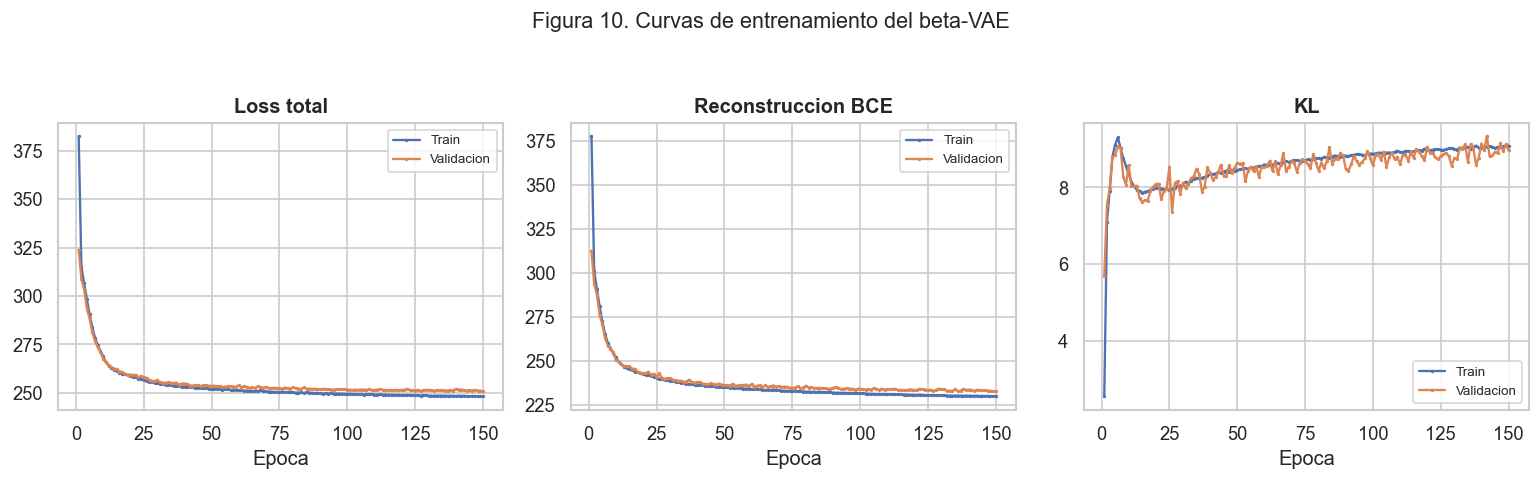

In [21]:
fig = plot_vae_history(vae_history, title="Figura 10. Curvas de entrenamiento del beta-VAE")
save_figure(fig, "figura_10_curvas_vae.png", FIGURES_DIR)
plt.show()

**Figura 10. Curvas de entrenamiento del beta-VAE.**

Con 150 epochs, la perdida total baja junto con el termino de reconstruccion. En validacion termina con loss **250.83**, reconstruccion **232.90** y KL **8.96**. El KL queda mucho mas chico que reconstruccion, pero no desaparece; eso es lo que fuerza al latente a parecerse a una normal estandar. Tambien achique los puntos del grafico para que las curvas sean mas legibles.

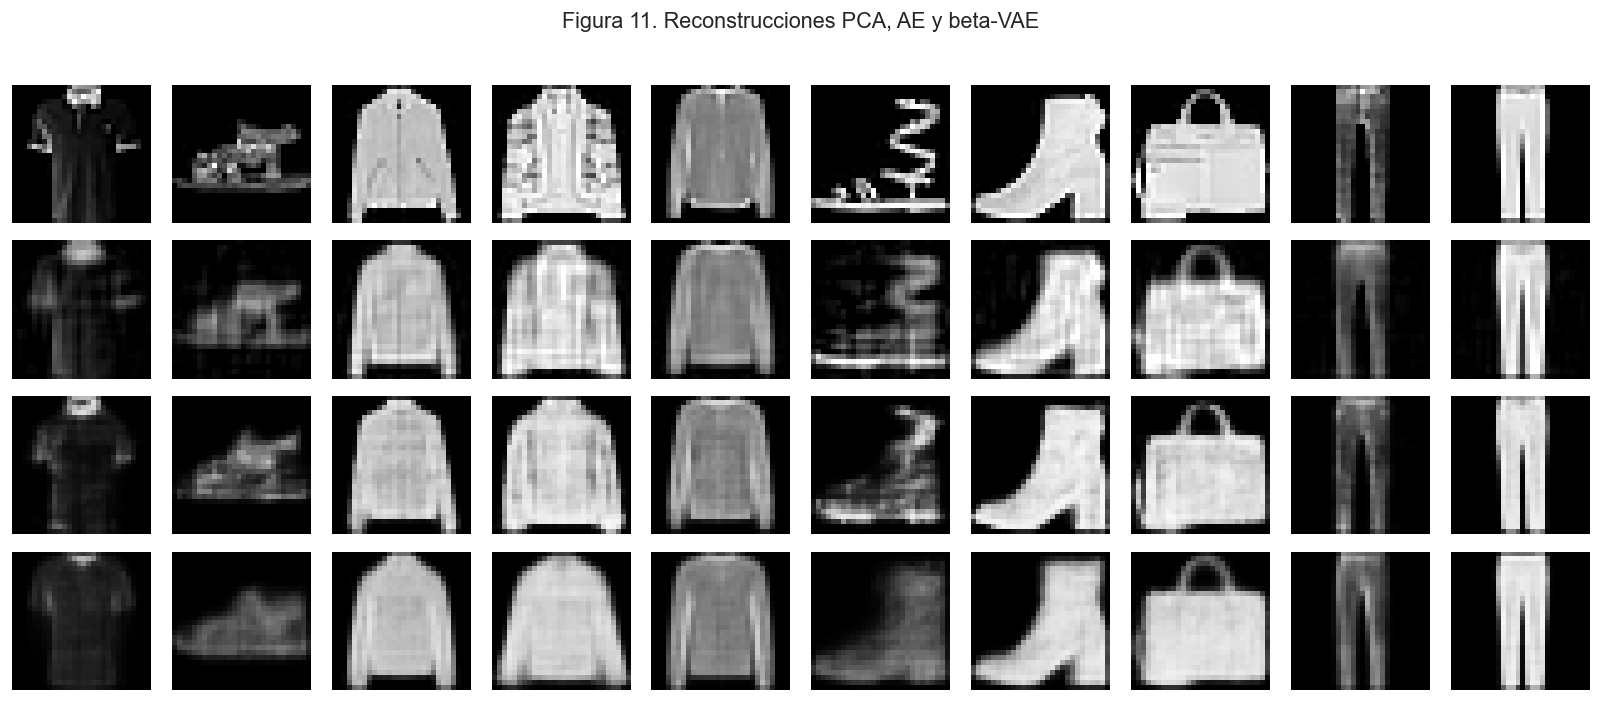

In [22]:
X_eval_vae_hat = reconstruct_vae(vae, X_eval, device=device)
mse_vae = reconstruction_mse(X_eval[idx_recon], X_eval_vae_hat[idx_recon])

fig = plot_reconstruction_rows(
    X_eval[idx_recon],
    {
        "PCA": X_eval_pca_hat[idx_recon],
        "AE": X_eval_ae_hat[idx_recon],
        "beta-VAE": X_eval_vae_hat[idx_recon],
    },
    ["PCA", "AE", "beta-VAE"],
    title="Figura 11. Reconstrucciones PCA, AE y beta-VAE",
    n=10,
)
save_figure(fig, "figura_11_reconstrucciones_pca_ae_vae.png", FIGURES_DIR)
plt.show()

**Figura 11. Reconstrucciones PCA, AE y beta-VAE.**

Con AE y beta-VAE entrenados 150 epochs, las reconstrucciones mejoran respecto de corridas mas cortas. PCA y AE quedan cerca en esta muestra, con PCA levemente mejor en MSE. El beta-VAE queda en **0.01833** y se ve mas suave, que era esperable porque no optimiza solo reconstruccion: tambien regulariza el espacio latente.

In [23]:
pd.DataFrame(
    {"MSE_10_imagenes": [mse_pca, mse_ae, mse_vae]},
    index=["PCA", "AE", "beta-VAE"],
)

,MSE_10_imagenes
PCA,0.009442
AE,0.010136
beta-VAE,0.018330


#### Experimento opcional 1: promediar embeddings de una misma clase

Selecciono cuatro imagenes de validacion de una misma clase, calculo sus embeddings y promedio en el espacio latente. Despues decodifico ese promedio con AE y con beta-VAE.

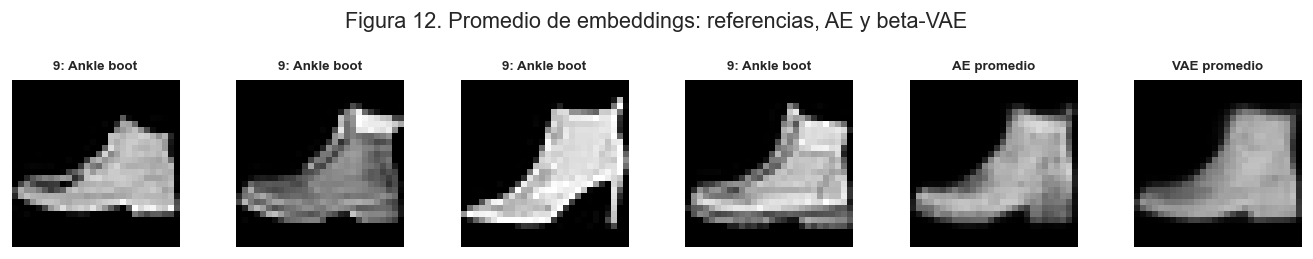

In [24]:
vae_eval_mu = encode_vae(vae, X_eval, device=device)
ae_eval_z = encode_autoencoder(ae, X_eval, device=device)

target_class = 9
class_positions = np.flatnonzero(y_eval == target_class)
chosen_same_class = class_positions[:4]

ae_mean_z = ae_eval_z[chosen_same_class].mean(axis=0, keepdims=True)
vae_mean_z = vae_eval_mu[chosen_same_class].mean(axis=0, keepdims=True)

ae_mean_img = decode_autoencoder(ae, ae_mean_z, device=device)
vae_mean_img = decode_vae(vae, vae_mean_z, device=device)

images_avg_experiment = np.vstack([X_eval[chosen_same_class], ae_mean_img, vae_mean_img])
labels_avg = [target_class] * 4 + [target_class, target_class]

fig = plot_images(
    images_avg_experiment,
    labels=labels_avg,
    n_cols=6,
    title="Figura 12. Promedio de embeddings: referencias, AE y beta-VAE",
)
axes = fig.axes
axes[4].set_title("AE promedio", fontsize=8)
axes[5].set_title("VAE promedio", fontsize=8)
save_figure(fig, "figura_12_promedio_embeddings.png", FIGURES_DIR)
plt.show()

**Figura 12. Promedio de embeddings de una misma clase.**

Use imagenes de botas de la misma clase. Al promediar embeddings, el AE genera una especie de bota intermedia, algo difusa. El beta-VAE tambien da una imagen promedio, pero mas suavizada. Esto tiene sentido porque el VAE intenta ordenar mejor el espacio latente, aunque pague con menos detalle.

#### Experimento opcional 2: muestrear $z \sim \mathcal{N}(0,I)$

Ahora pruebo algo mas exigente: generar vectores aleatorios desde una normal estandar y decodificarlos con AE y beta-VAE.

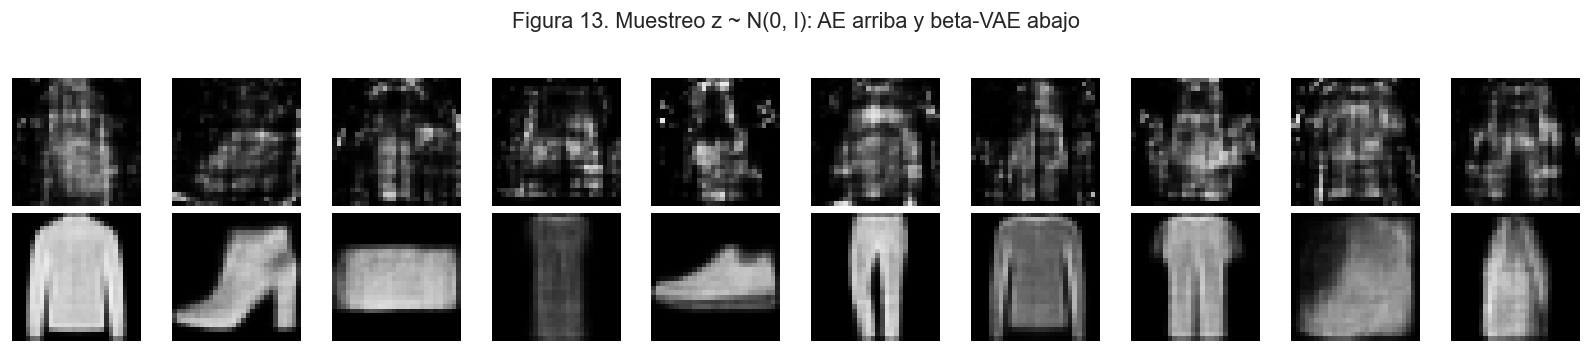

In [25]:
rng = np.random.default_rng(SEED)
z_random = rng.normal(0, 1, size=(10, K_PCA)).astype(np.float32)

ae_random_imgs = decode_autoencoder(ae, z_random, device=device)
vae_random_imgs = decode_vae(vae, z_random, device=device)

fig = plot_reconstruction_rows(
    ae_random_imgs,
    {"beta-VAE": vae_random_imgs},
    ["beta-VAE"],
    title="Figura 13. Muestreo z ~ N(0, I): AE arriba y beta-VAE abajo",
    n=10,
)
fig.axes[0].set_ylabel("AE", rotation=0, ha="right", va="center", fontsize=9)
save_figure(fig, "figura_13_muestreo_normal.png", FIGURES_DIR)
plt.show()

**Figura 13. Muestreo $z \sim \mathcal{N}(0,I)$.**

Este experimento me sirvio para ver la diferencia mas conceptual entre AE y VAE. El AE reconstruye bien sus propios codigos, pero no fue entrenado para que cualquier punto normal sea valido. El beta-VAE, en cambio, empuja sus embeddings hacia $\mathcal{N}(0,I)$, entonces tiene mas sentido decodificar puntos muestreados de esa distribucion.

## 3. Clustering

Trabajo con una muestra estratificada de 3000 puntos, como pide la consigna. Para cada espacio (`PCA` y `AE`) pruebo $K \in [5,15]$.

### k-Means

El objetivo de k-Means es minimizar la suma de distancias cuadraticas a los centroides:

$$
\mu_j^*, r_{ij}^* =
\arg\min_{\mu_j,r_{ij}}
\sum_{i=1}^{N}\sum_{j=1}^{K} r_{ij}\lVert x_i-\mu_j\rVert^2
$$

con $r_{ij}\in\{0,1\}$ y $\sum_j r_{ij}=1$. La implementacion alterna asignar cada muestra al centroide mas cercano y actualizar cada centroide como el promedio de las muestras asignadas.

### GMM

En GMM cada punto tiene responsabilidades suaves:

$$
\gamma(z_{ij}) =
\frac{\pi_j \mathcal{N}(x_i|\mu_j,\Sigma_j)}
{\sum_{\ell=1}^{K}\pi_\ell \mathcal{N}(x_i|\mu_\ell,\Sigma_\ell)}
$$

Luego EM alterna:

$$
N_j=\sum_i \gamma(z_{ij}), \qquad
\mu_j=\frac{1}{N_j}\sum_i \gamma(z_{ij})x_i
$$

$$
\Sigma_j=\frac{1}{N_j}\sum_i\gamma(z_{ij})(x_i-\mu_j)(x_i-\mu_j)^T,
\qquad
\pi_j=\frac{N_j}{N}
$$

Para que sea estable en dimension 135 con 3000 muestras, uso una GMM con covarianza diagonal. Es la misma idea de mezcla Gaussiana, pero restringiendo $\Sigma_j$ a una matriz diagonal.

### Silhouette

Para evaluar separacion interna uso Silhouette:

$$
s_i = \frac{b_i-a_i}{\max(a_i,b_i)}
$$

donde $a_i$ es la distancia promedio al propio cluster y $b_i$ es la menor distancia promedio a otro cluster. Valores mas altos indican clusters mas separados.

In [26]:
sample_idx = stratified_sample_indices(y, n_samples=3000, seed=SEED)
y_cluster = y[sample_idx]
X_cluster = X[sample_idx]
Z_cluster_pca = Z_all_pca_for_cluster[sample_idx]
Z_cluster_ae = Z_all_ae_scaled[sample_idx]

sample_counts = pd.Series(y_cluster).value_counts().sort_index().rename(index=LABEL_NAMES)
sample_counts.to_frame("muestras_en_clustering")

,muestras_en_clustering
T-shirt/top,300
Trouser,300
Pullover,300
Dress,300
Coat,300
Sandal,300
Shirt,300
Sneaker,300
Bag,300
Ankle boot,300


In [27]:
def add_kmeans_gains(df):
    df = df.copy()
    prev = df["inertia"].shift(1)
    df["gain_inertia"] = ((prev - df["inertia"]) / prev).fillna(0.0)
    return df


def add_gmm_gains(df):
    df = df.copy()
    df["gain_loglik"] = df["avg_log_likelihood"].diff().fillna(0.0)
    return df


def evaluate_kmeans_range(Z, name, k_values=range(5, 16)):
    distances = pairwise_distances(Z)
    records = []
    models = {}
    for k in k_values:
        result = kmeans(Z, k, max_iter=100, n_init=20, seed=SEED + k)
        sil = silhouette_score_from_distances(distances, result["labels"])
        models[k] = result
        records.append({"espacio": name, "k": k, "inertia": result["inertia"], "silhouette": sil})
    return add_kmeans_gains(pd.DataFrame(records)), models


def evaluate_gmm_range(Z, name, k_values=range(5, 16)):
    distances = pairwise_distances(Z)
    records = []
    models = {}
    for k in k_values:
        result = gmm_diag(Z, k, max_iter=35, n_init=1, seed=SEED + 10 * k, min_var=1e-3)
        sil = silhouette_score_from_distances(distances, result["labels"])
        models[k] = result
        records.append(
            {
                "espacio": name,
                "k": k,
                "avg_log_likelihood": result["avg_log_likelihood"],
                "silhouette": sil,
            }
        )
    return add_gmm_gains(pd.DataFrame(records)), models

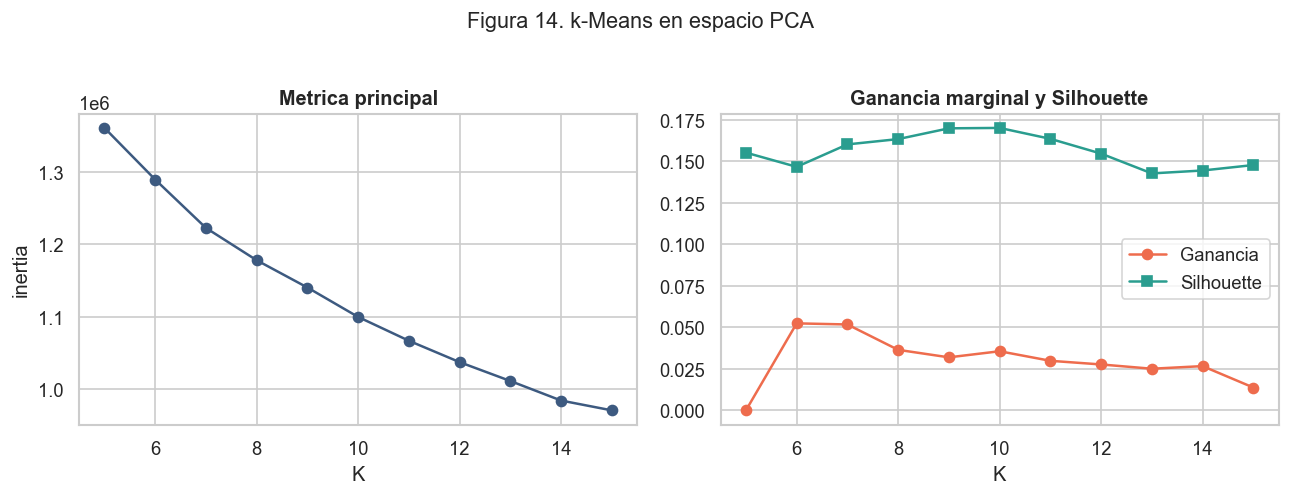

In [28]:
kmeans_pca_df, kmeans_pca_models = evaluate_kmeans_range(Z_cluster_pca, "PCA")
kmeans_pca_df.to_csv(CSV_DIR / "kmeans_pca_results.csv", index=False)

fig = plot_cluster_metrics(
    kmeans_pca_df,
    metric_col="inertia",
    gain_col="gain_inertia",
    title="Figura 14. k-Means en espacio PCA",
)
save_figure(fig, "figura_14_kmeans_pca.png", FIGURES_DIR)
plt.show()

**Figura 14. k-Means en espacio PCA.**

La inercia baja al aumentar $K$, como era esperable. En Silhouette el mejor valor aparece cerca de $K=10$, justo la cantidad de clases reales del dataset, aunque el metodo no uso esas etiquetas para entrenar. Igual el valor no es alto, asi que no lo interpretaria como clusters perfectamente separados.

In [29]:
kmeans_pca_df

,espacio,k,inertia,silhouette,gain_inertia
0,PCA,5,1.360617e+06,0.155311,0.000000
1,PCA,6,1.289276e+06,0.146736,0.052433
2,PCA,7,1.222538e+06,0.160267,0.051765
3,PCA,8,1.177944e+06,0.163464,0.036476
4,PCA,9,1.140302e+06,0.169948,0.031955
5,PCA,10,1.099675e+06,0.170191,0.035629
6,PCA,11,1.066825e+06,0.163621,0.029872
7,PCA,12,1.037308e+06,0.154718,0.027669
8,PCA,13,1.011280e+06,0.142784,0.025092
9,PCA,14,9.843087e+05,0.144532,0.026670


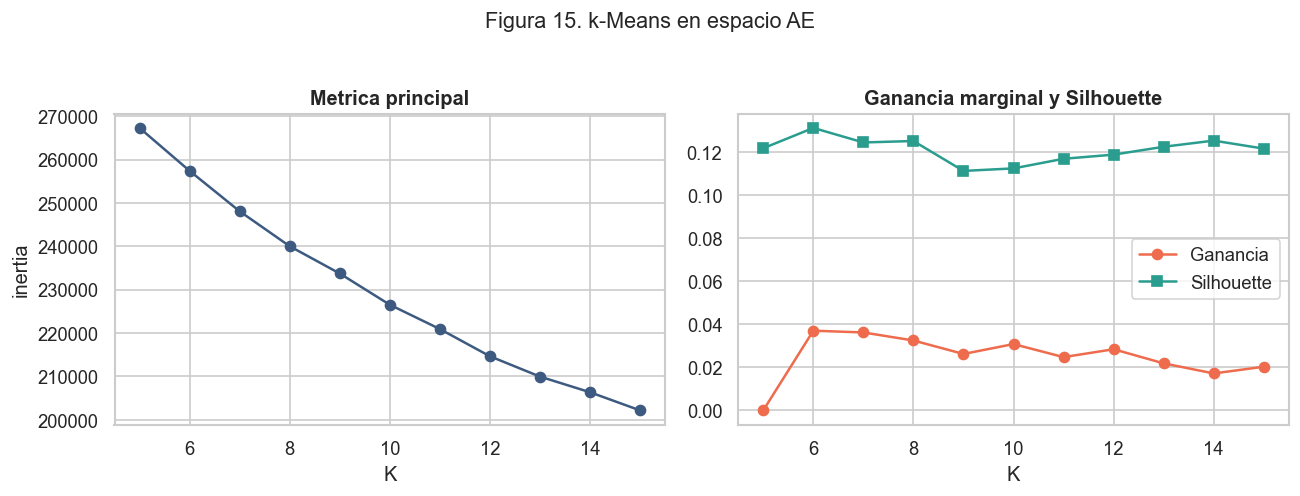

In [30]:
kmeans_ae_df, kmeans_ae_models = evaluate_kmeans_range(Z_cluster_ae, "AE")
kmeans_ae_df.to_csv(CSV_DIR / "kmeans_ae_results.csv", index=False)

fig = plot_cluster_metrics(
    kmeans_ae_df,
    metric_col="inertia",
    gain_col="gain_inertia",
    title="Figura 15. k-Means en espacio AE",
)
save_figure(fig, "figura_15_kmeans_ae.png", FIGURES_DIR)
plt.show()

**Figura 15. k-Means en espacio AE.**

El AE reconstruye mejor despues de entrenar mas, pero eso no se traduce automaticamente en mejores clusters. En este caso los Silhouette del espacio AE quedan por debajo del mejor k-Means sobre PCA. El mejor valor aparece en $K=6$ con **0.1312**. Para mi esto muestra que reconstruir bien y separar clases no son el mismo objetivo.

In [31]:
kmeans_ae_df

,espacio,k,inertia,silhouette,gain_inertia
0,AE,5,267281.062500,0.121767,0.000000
1,AE,6,257386.718750,0.131207,0.037018
2,AE,7,248070.109375,0.124452,0.036197
3,AE,8,240016.593750,0.125130,0.032465
4,AE,9,233728.156250,0.111233,0.026200
5,AE,10,226528.656250,0.112407,0.030803
6,AE,11,220925.828125,0.116878,0.024733
7,AE,12,214651.515625,0.118795,0.028400
8,AE,13,209962.578125,0.122455,0.021844
9,AE,14,206358.812500,0.125313,0.017164


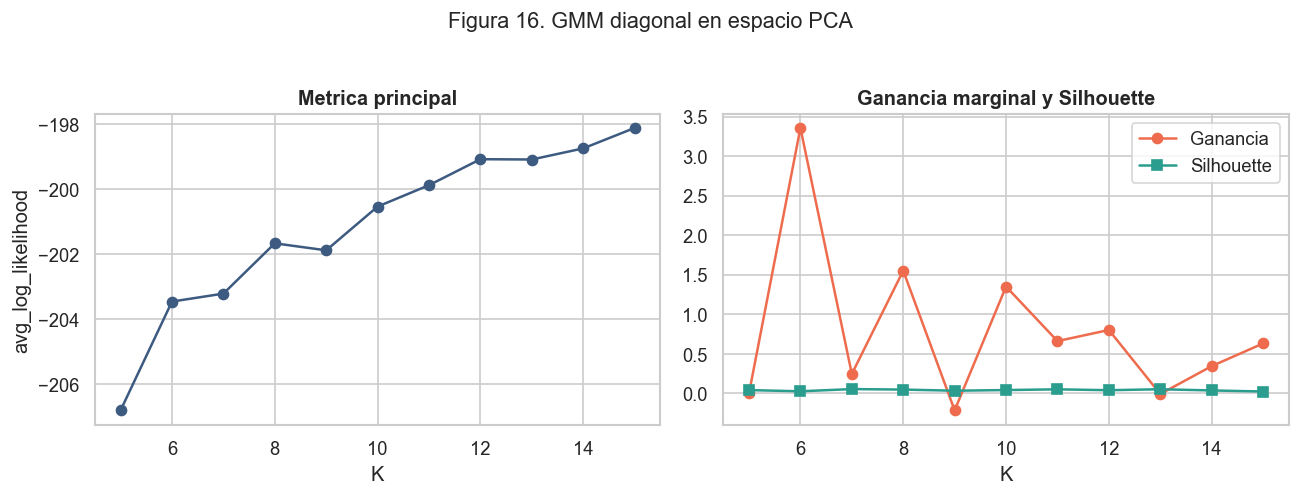

In [32]:
gmm_pca_df, gmm_pca_models = evaluate_gmm_range(Z_cluster_pca, "PCA")
gmm_pca_df.to_csv(CSV_DIR / "gmm_pca_results.csv", index=False)

fig = plot_cluster_metrics(
    gmm_pca_df,
    metric_col="avg_log_likelihood",
    gain_col="gain_loglik",
    title="Figura 16. GMM diagonal en espacio PCA",
)
save_figure(fig, "figura_16_gmm_pca.png", FIGURES_DIR)
plt.show()

**Figura 16. GMM diagonal en espacio PCA.**

La log-verosimilitud promedio tiende a mejorar cuando aumenta $K$, pero el Silhouette queda bajo. O sea, la GMM ajusta mejor densidad con mas componentes, pero eso no significa que las asignaciones sean grupos bien separados. Por eso para el mapa final me resulto mas claro usar k-Means sobre PCA.

In [33]:
gmm_pca_df

,espacio,k,avg_log_likelihood,silhouette,gain_loglik
0,PCA,5,-206.820501,0.040389,0.000000
1,PCA,6,-203.464138,0.025385,3.356363
2,PCA,7,-203.219261,0.053274,0.244877
3,PCA,8,-201.668258,0.047069,1.551004
4,PCA,9,-201.884282,0.032658,-0.216024
5,PCA,10,-200.534553,0.040903,1.349729
6,PCA,11,-199.874483,0.050207,0.660070
7,PCA,12,-199.073698,0.039031,0.800785
8,PCA,13,-199.083151,0.051245,-0.009453
9,PCA,14,-198.739597,0.036068,0.343553


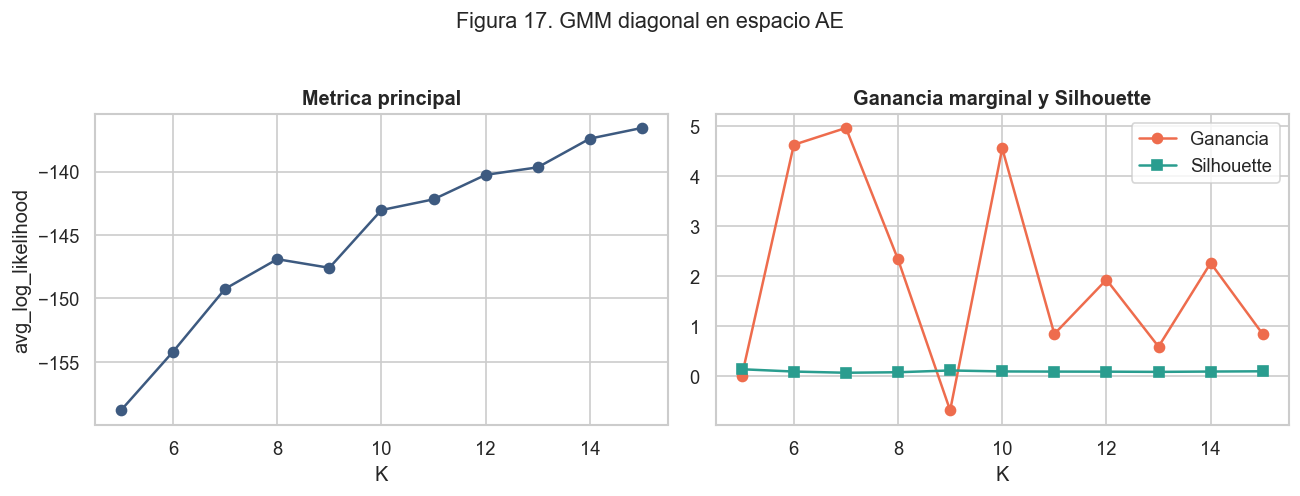

In [34]:
gmm_ae_df, gmm_ae_models = evaluate_gmm_range(Z_cluster_ae, "AE")
gmm_ae_df.to_csv(CSV_DIR / "gmm_ae_results.csv", index=False)

fig = plot_cluster_metrics(
    gmm_ae_df,
    metric_col="avg_log_likelihood",
    gain_col="gain_loglik",
    title="Figura 17. GMM diagonal en espacio AE",
)
save_figure(fig, "figura_17_gmm_ae.png", FIGURES_DIR)
plt.show()

**Figura 17. GMM diagonal en espacio AE.**

En AE pasa algo parecido: la likelihood mejora con mas componentes, pero el Silhouette oscila. El mejor valor aparece en $K=5$ con **0.1418**. No use BIC/AIC porque la consigna pedia ganancias decrecientes y Silhouette; por eso mire la likelihood como referencia, no como criterio principal.

In [35]:
gmm_ae_df

,espacio,k,avg_log_likelihood,silhouette,gain_loglik
0,AE,5,-158.824528,0.141845,0.000000
1,AE,6,-154.199983,0.095680,4.624545
2,AE,7,-149.238874,0.071703,4.961109
3,AE,8,-146.904440,0.081854,2.334434
4,AE,9,-147.584094,0.117482,-0.679654
5,AE,10,-143.031662,0.097884,4.552432
6,AE,11,-142.185801,0.094876,0.845861
7,AE,12,-140.255560,0.093569,1.930241
8,AE,13,-139.662316,0.089163,0.593245
9,AE,14,-137.399212,0.095820,2.263103


In [36]:
summary_rows = []
for metodo, espacio, df_res in [
    ("k-Means", "PCA", kmeans_pca_df),
    ("k-Means", "AE", kmeans_ae_df),
    ("GMM", "PCA", gmm_pca_df),
    ("GMM", "AE", gmm_ae_df),
]:
    best_row = df_res.loc[df_res["silhouette"].idxmax()]
    summary_rows.append(
        {
            "metodo": metodo,
            "espacio": espacio,
            "mejor_K_por_silhouette": int(best_row["k"]),
            "silhouette": float(best_row["silhouette"]),
        }
    )

cluster_choice_summary = pd.DataFrame(summary_rows)
cluster_choice_summary

,metodo,espacio,mejor_K_por_silhouette,silhouette
0,k-Means,PCA,10,0.170191
1,k-Means,AE,6,0.131207
2,GMM,PCA,7,0.053274
3,GMM,AE,5,0.141845


In [37]:
# Para el t-SNE final la consigna pide usar el espacio PCA, entonces elijo
# entre k-Means y GMM sobre PCA segun Silhouette.
best_km_pca = kmeans_pca_df.loc[kmeans_pca_df["silhouette"].idxmax()]
best_gmm_pca = gmm_pca_df.loc[gmm_pca_df["silhouette"].idxmax()]

if best_km_pca["silhouette"] >= best_gmm_pca["silhouette"]:
    selected_method = "k-Means"
    selected_k = int(best_km_pca["k"])
    selected_model = kmeans_pca_models[selected_k]
else:
    selected_method = "GMM"
    selected_k = int(best_gmm_pca["k"])
    selected_model = gmm_pca_models[selected_k]

selected_labels = selected_model["labels"]
selected_silhouette = silhouette_score_from_distances(pairwise_distances(Z_cluster_pca), selected_labels)
selected_purity = total_purity(selected_labels, y_cluster)

selected_info = pd.DataFrame(
    {
        "metodo": [selected_method],
        "K": [selected_k],
        "silhouette": [selected_silhouette],
        "pureza_externa": [selected_purity],
    }
)
selected_info

,metodo,K,silhouette,pureza_externa
0,k-Means,10,0.170191,0.520667


Para el mapa final uso **k-Means con $K=10$ sobre PCA**, porque fue la mejor combinacion en el espacio PCA segun Silhouette (**0.1702**). La pureza externa, usando etiquetas solo para evaluar, es **0.5207**. Que $K$ quede cerca de 10 es razonable, pero la pureza muestra que varias clases de ropa superior siguen mezclandose.

### 3.d t-SNE propio sobre el latente PCA

La consigna pide graficar en 2D usando una implementacion propia de t-SNE aplicada sobre el espacio latente PCA. t-SNE construye similitudes en alta dimension:

$$
p_{j|i} =
\frac{\exp(-\lVert x_i-x_j\rVert^2 / 2\sigma_i^2)}
{\sum_{k\neq i}\exp(-\lVert x_i-x_k\rVert^2 / 2\sigma_i^2)}
$$

Despues simetriza:

$$
p_{ij}=\frac{p_{j|i}+p_{i|j}}{2N}
$$

En 2D usa una distribucion t-Student:

$$
q_{ij} =
\frac{(1+\lVert y_i-y_j\rVert^2)^{-1}}
{\sum_{k\neq l}(1+\lVert y_k-y_l\rVert^2)^{-1}}
$$

y minimiza:

$$
KL(P\Vert Q)=\sum_{i\neq j}p_{ij}\log\frac{p_{ij}}{q_{ij}}
$$

In [38]:
Y_tsne, tsne_history = tsne_embedding(
    Z_cluster_pca,
    perplexity=30,
    n_iter=350,
    learning_rate=200,
    early_exaggeration=12,
    exaggeration_iters=80,
    seed=SEED,
)

tsne_history.to_csv(CSV_DIR / "tsne_history.csv", index=False)
tsne_history.tail()

,iter,kl
3,150,2.234993
4,200,2.026693
5,250,1.900311
6,300,1.724049
7,350,1.616865


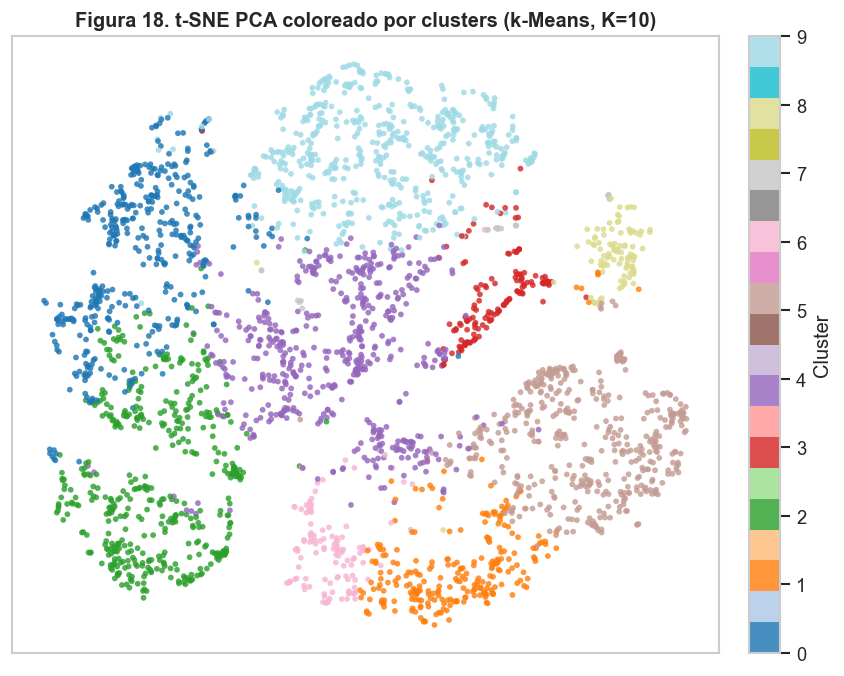

In [39]:
fig = plot_tsne(
    Y_tsne,
    selected_labels,
    title=f"Figura 18. t-SNE PCA coloreado por clusters ({selected_method}, K={selected_k})",
    palette="tab20",
    colorbar_label="Cluster",
)
save_figure(fig, "figura_18_tsne_clusters.png", FIGURES_DIR)
plt.show()

**Figura 18. t-SNE coloreado por clusters.**

El mapa muestra algunas zonas separadas y otras con transicion gradual. Eso coincide con el Silhouette moderado: hay estructura, pero no bloques perfectamente aislados. Algunos clusters parecen capturar grupos grandes de prendas, y otros grupos mas especificos.

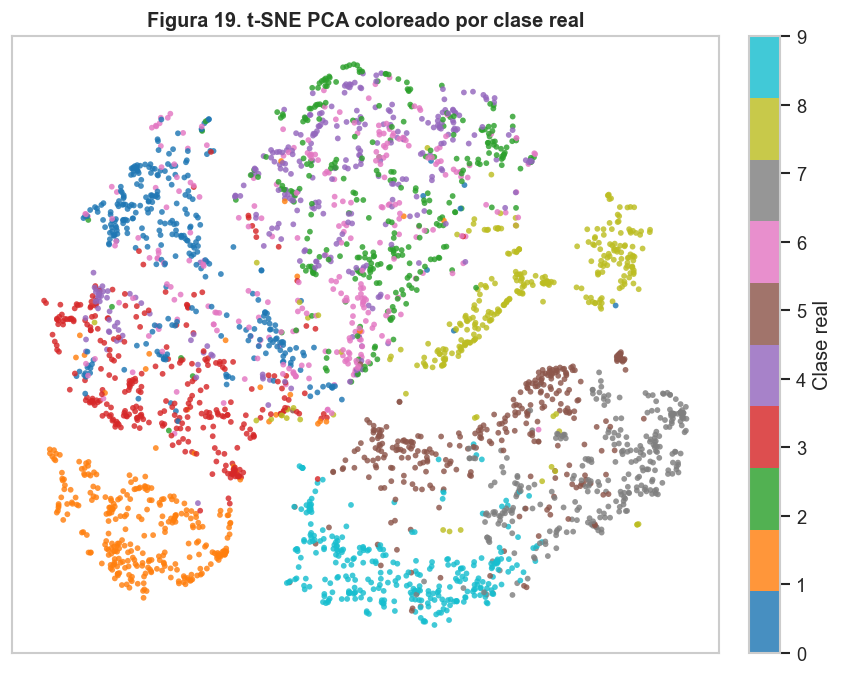

In [40]:
fig = plot_tsne(
    Y_tsne,
    y_cluster,
    title="Figura 19. t-SNE PCA coloreado por clase real",
    palette="tab10",
    colorbar_label="Clase real",
)
save_figure(fig, "figura_19_tsne_clases_reales.png", FIGURES_DIR)
plt.show()

**Figura 19. t-SNE coloreado por clase real.**

Al colorear por etiqueta real se entiende mejor que pasa. Calzado y bolsos tienden a aparecer en zonas mas limpias, mientras que las prendas superiores se mezclan bastante. Esto explica por que el clustering no llega a una pureza muy alta: visualmente esas clases son cercanas.

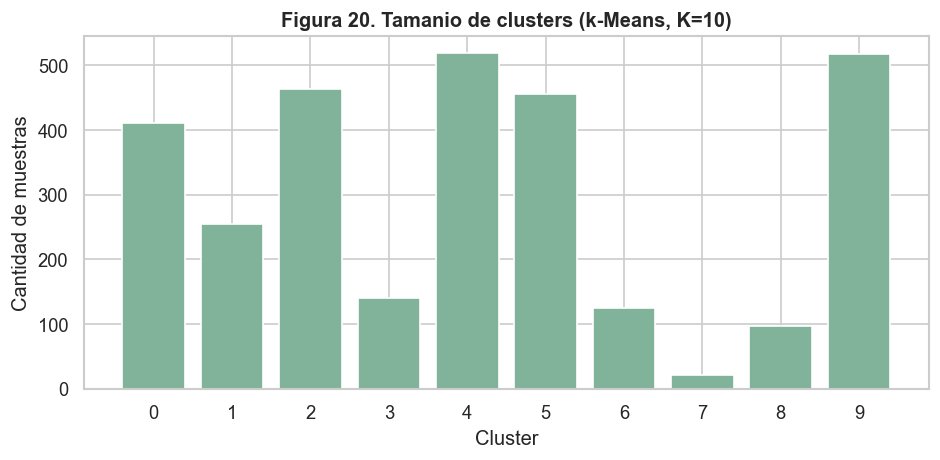

In [41]:
summary_selected = cluster_summary(selected_labels, y_cluster)
fig = plot_cluster_sizes(
    summary_selected,
    title=f"Figura 20. Tamanio de clusters ({selected_method}, K={selected_k})",
)
save_figure(fig, "figura_20_tamanio_clusters.png", FIGURES_DIR)
plt.show()

**Figura 20. Tamanio de los clusters seleccionados.**

Los tamanios no son uniformes: hay clusters grandes y otros chicos. No lo veo necesariamente como un error, porque algunas familias de imagenes tienen mas variabilidad que otras. Pero si muestra que k-Means no esta copiando una particion balanceada uno a uno con las etiquetas reales.

In [42]:
summary_selected

,cluster,n,clase_dominante,nombre,pureza
0,0,410,0,T-shirt/top,0.492683
1,1,254,9,Ankle boot,0.700787
2,2,463,1,Trouser,0.578834
3,3,140,8,Bag,0.885714
4,4,519,6,Shirt,0.227360
5,5,456,7,Sneaker,0.554825
6,6,124,9,Ankle boot,0.879032
7,7,21,8,Bag,0.666667
8,8,96,8,Bag,1.000000
9,9,517,4,Coat,0.386847


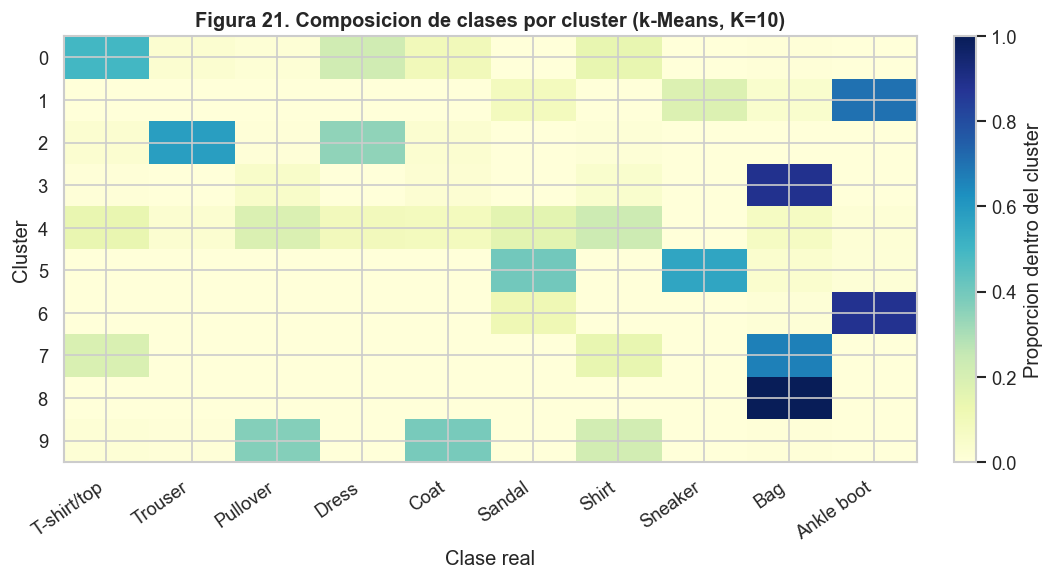

In [43]:
table_selected = cluster_class_table(selected_labels, y_cluster)
fig = plot_cluster_heatmap(
    table_selected,
    title=f"Figura 21. Composicion de clases por cluster ({selected_method}, K={selected_k})",
)
save_figure(fig, "figura_21_composicion_clusters.png", FIGURES_DIR)
plt.show()

**Figura 21. Composicion de clases por cluster.**

La matriz confirma lo que se veia en t-SNE. Algunos clusters tienen una clase dominante clara, pero otros mezclan varias prendas superiores. La pureza promedio por cluster es **0.637**, mientras que la pureza total ponderada queda cerca de **0.521**. Para mi, el resultado es razonable para datos no supervisados y clases visualmente parecidas.

In [44]:
table_selected

clase,0,1,2,3,4,5,6,7,8,9
cluster,,,,,,,,,,
0,202,12,5,90,40,0,59,0,2,0
1,0,0,0,0,0,21,0,46,9,178
2,13,268,3,160,13,0,5,0,0,1
3,1,0,7,0,3,0,5,0,124,0
4,71,16,96,48,44,83,118,1,35,7
5,1,0,0,0,0,182,0,253,15,5
6,0,0,0,0,0,14,0,0,1,109
7,4,0,0,0,0,0,3,0,14,0
8,0,0,0,0,0,0,0,0,96,0


In [45]:
mean_cluster_size = summary_selected["n"].mean()
min_cluster_size = summary_selected["n"].min()
max_cluster_size = summary_selected["n"].max()
mean_purity = summary_selected["pureza"].mean()

pd.DataFrame(
    {
        "min_muestras": [min_cluster_size],
        "max_muestras": [max_cluster_size],
        "promedio_muestras": [mean_cluster_size],
        "pureza_promedio_cluster": [mean_purity],
    }
)

,min_muestras,max_muestras,promedio_muestras,pureza_promedio_cluster
0,21,519,300.0,0.637275


## Cierre del analisis computacional

El notebook queda como respaldo tecnico del informe: inspeccion de datos, split estratificado, PCA desde cero, AE y beta-VAE con la misma dimension latente, comparacion de reconstrucciones, clustering con k-Means y GMM diagonal, seleccion de $K$, t-SNE propio y analisis de homogeneidad de clusters.

Las figuras estan guardadas en `figures/` y las salidas tabulares principales en `csvs/`.